# Figure 4 - CryoEM Data

In [1]:
# access fsw3d library by adding project root to sys.path
import sys, os
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '..')))

### standard libraries
import time
import numpy as np
import matplotlib.pyplot as plt

### other
import mrcfile

### fsw3d
from fast_volume_align_ot import utils, plots, transforms, signals, alignments, distances

In [2]:
###

### To run this notebook, you will first need to download the 
### simulated models from the cryoDRGN paper 

### data : https://zenodo.org/records/4355284
### ref  : https://doi.org/10.1038/s41592-020-01049-4

###

In [3]:
#######################################


### *** HETEROGENEOUS DISTANCE *** ###


#######################################

In [4]:
COLORS = {
    'l2': 'darkgrey',
    'sw': '#8FB996',
    'rfsw': '#7C8ED0'
}

In [5]:
### INPUTS

n_vols = 25

het_vol_files = '../3D_Data/het_models/'

het_vols = []
vol_idx = np.linspace(0, 49, n_vols, endpoint=True).astype('int')

for k in vol_idx:
    with mrcfile.open(het_vol_files+'{}'.format(k)+'.mrc', permissive=True) as mrc:
        v = mrc.data
        dx = mrc.voxel_size.x
        # v = np.pad(v, pad_width=((0, 1), (0, 1), (0, 1)))  ### zero-pad to make odd size  
        v = signals.Signal(v, d=3, dx=dx).preprocess_signals()[0]        
        het_vols.append(v)
        mrc.close()

het_vols = np.array(het_vols)

f = het_vols[0].copy()

N = f.shape[0]
grid = transforms.Grids(N=N)

/Users/Eric-Verbeke/miniforge3/envs/fsw3d/lib/python3.9/site-packages/mrcfile/mrcinterpreter.py:206: RuntimeWarning: Map ID string not found - not an MRC file, or file is corrupt
  warnings.warn(msg, RuntimeWarning)
/Users/Eric-Verbeke/miniforge3/envs/fsw3d/lib/python3.9/site-packages/mrcfile/mrcinterpreter.py:216: RuntimeWarning: Unrecognised machine stamp: 0x00 0x00 0x00 0x00
  warnings.warn(str(err), RuntimeWarning)


In [6]:
### Compute the squared distances

distances_l2 = np.zeros(n_vols)
distances_sw = np.zeros(n_vols)
distances_rfsw = np.zeros(n_vols)

f_t = transforms.Transform(f, d=3, grid=grid).inverse_cdf_transform()[0]
f_tp, f_tn = transforms.Transform(f, d=3, grid=grid, apply_ramp=True).signed_inverse_cdf_transform()
f_tp, f_tn = f_tp[0], f_tn[0]

for k in range(n_vols):

    g = het_vols[k]

    ### Euclidean distance
    d_l2 = distances.compute_3d_density_l2_distance(f, g, grid)
    distances_l2[k] = d_l2

    ### sliced 2-Wasserstein distance
    g_t = transforms.Transform(g, d=3, grid=grid).inverse_cdf_transform()[0]
    d_sw = distances.compute_3d_sliced_wasserstein_distance(f_t, g_t, grid) / (4*np.pi)
    distances_sw[k] = d_sw

    ### ramp-filtered sliced 2-Wasserstein distance
    g_tp, g_tn = transforms.Transform(g, d=3, grid=grid, apply_ramp=True).signed_inverse_cdf_transform()
    g_tp, g_tn = g_tp[0], g_tn[0]
    d_sw_p = distances.compute_3d_sliced_wasserstein_distance(f_tp, g_tp, grid) / (4*np.pi)
    d_sw_n = distances.compute_3d_sliced_wasserstein_distance(f_tn, g_tn, grid) / (4*np.pi)
    d_rfsw = (d_sw_p + d_sw_n) / 2
    distances_rfsw[k] = d_rfsw

dists_l2 = np.sqrt( distances_l2 / np.amax(distances_l2) )
dists_sw = np.sqrt( distances_sw / np.amax(distances_sw) )
dists_rfsw = np.sqrt( distances_rfsw / np.amax(distances_rfsw) )

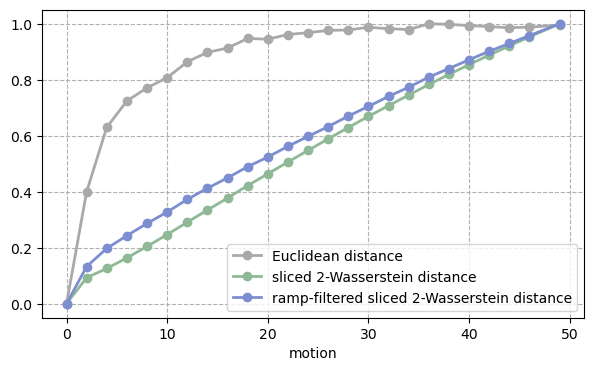

In [7]:
fig, ax = plt.subplots(1, figsize=(7,4))
ax.plot(vol_idx, dists_l2, color=COLORS['l2'], marker='o', linewidth=2, 
        label='Euclidean distance')
ax.plot(vol_idx, dists_sw, color=COLORS['sw'], marker='o', linewidth=2, 
        label='sliced 2-Wasserstein distance')
plt.plot(vol_idx, dists_rfsw, color=COLORS['rfsw'], marker='o', linewidth=2,
         label='ramp-filtered sliced 2-Wasserstein distance')

ax.grid(which='major', linestyle='--')
plt.rc('xtick', labelsize=10)
plt.rc('ytick', labelsize=10)
ax.legend()
# ax.set_xticklabels([])
ax.set_xlabel('motion')
# plt.title('normalized distance')
# plt.savefig('Output/cryoEM_distance_3d.png', dpi=200, transparent=True)
plt.show()

In [8]:
#######################################


### *** ROTATIONAL ALIGNMENT *** ###


#######################################

In [9]:
f = het_vols[0].copy()
g = np.rot90(het_vols[-1].copy(), k=3)

N = f.shape[0]
grid = transforms.Grids(N=N)

In [10]:
t = time.time()
alignment_l2 = (alignments.Alignment(f, g, grid, metric='L2', use_correlation=False))
print("alignment L2   = ", time.time() - t)
print('\n')

t = time.time()
alignment_sw = (alignments.Alignment(f, g, grid, metric='SW', use_correlation=False))
print("alignment SW   = ", time.time() - t)
print('\n')

t = time.time()
alignment_rfsw = (alignments.Alignment(f, g, grid, metric='RFSW', use_correlation=False))
print("alignment RFSW = ", time.time() - t)
print('\n')

alignment L2   =  61.87227177619934




/Users/Eric-Verbeke/miniforge3/envs/fsw3d/lib/python3.9/site-packages/finufft/_interfaces.py:336: UserWarning: Argument `data` does not satisfy the following requirement: C. Copying array (this may reduce performance)
  warnings.warn(f"Argument `{name}` does not satisfy the following requirement: {prop}. Copying array (this may reduce performance)")


alignment SW   =  49.993358850479126




/Users/Eric-Verbeke/miniforge3/envs/fsw3d/lib/python3.9/site-packages/finufft/_interfaces.py:336: UserWarning: Argument `data` does not satisfy the following requirement: C. Copying array (this may reduce performance)
  warnings.warn(f"Argument `{name}` does not satisfy the following requirement: {prop}. Copying array (this may reduce performance)")


alignment RFSW =  96.94732999801636




In [11]:
def orthogonal_2D_projection_plot(volume, cmap='viridis', size=(10,5), save=False, save_path=''):
    
    fig, axs = plt.subplots(1, 3, figsize=size)
    
    p_z = axs[0].imshow(np.sum(volume, axis=2), cmap)
    axs[0].axis('off')
    p_y = axs[1].imshow(np.sum(volume, axis=1), cmap)
    axs[1].axis('off')
    p_x = axs[2].imshow(np.sum(volume, axis=0), cmap)
    axs[2].axis('off')

    plt.title('')
    plt.tight_layout()

    if save:
        plt.savefig(save_path, dpi=200, transparent=True)
    
    plt.show()

f - g


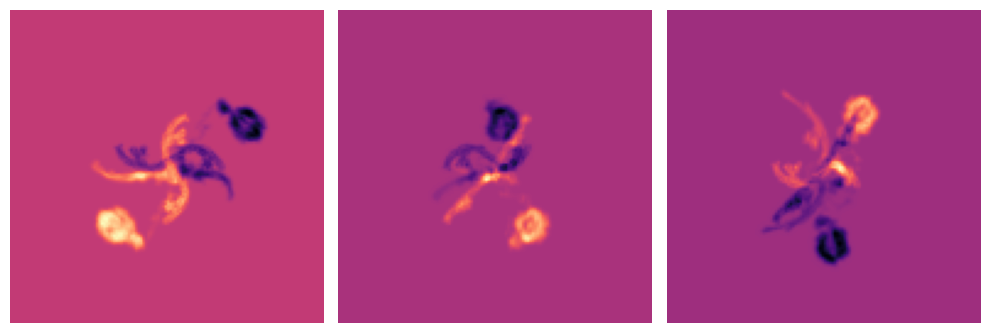

Euclidean distance


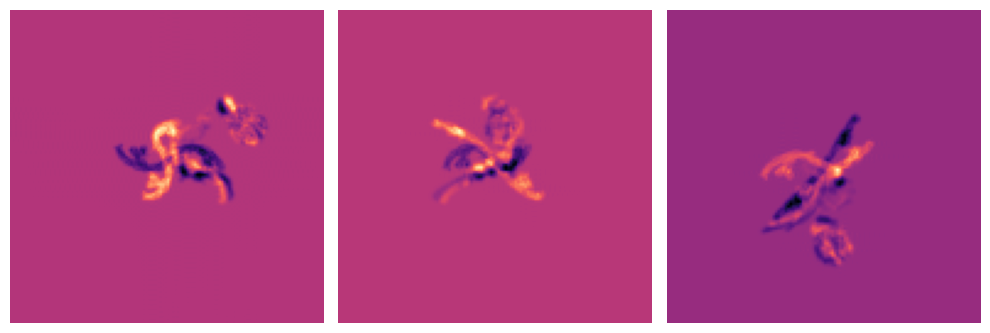

sliced 2-Wasserstein distance


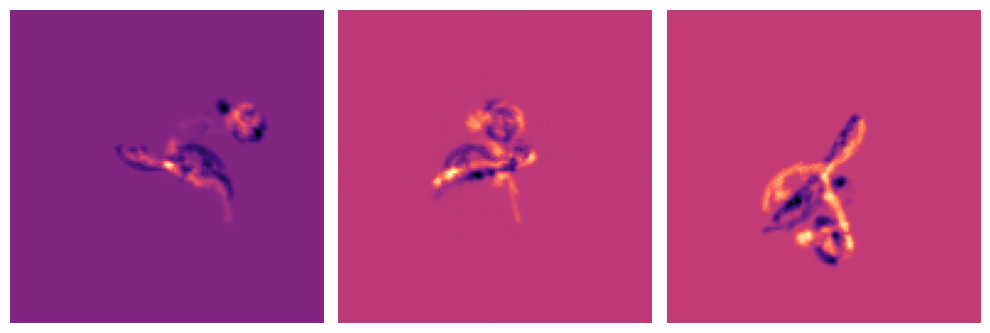

ramp-filtered sliced 2-Wasserstein distance


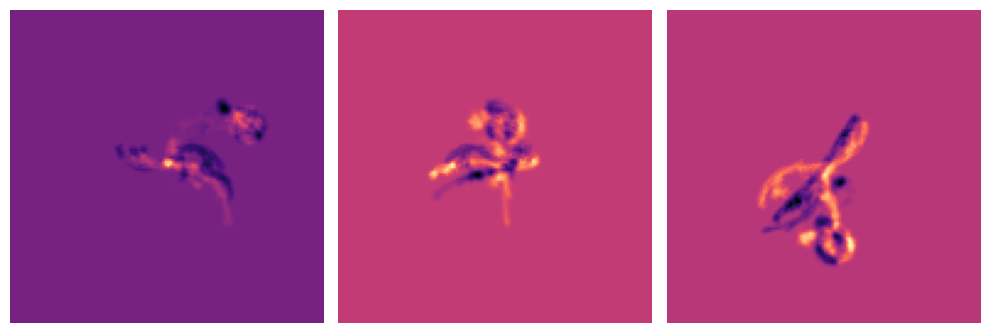

In [12]:
### add additional 90deg rotation to volumes to match perspective shown in Figure 5

save = False

print('f - g')
orthogonal_2D_projection_plot(np.rot90(f - g, 1), cmap='magma_r', 
                              save=save, save_path='Output/cryo_diff.png')
print('Euclidean distance')
orthogonal_2D_projection_plot(np.rot90(f - alignment_l2.aligned, 1), cmap='magma_r',
                              save=save, save_path='Output/cryo_l2.png')
print('sliced 2-Wasserstein distance')
orthogonal_2D_projection_plot(np.rot90(f - alignment_sw.aligned, 1), cmap='magma_r', 
                              save=save, save_path='Output/cryo_sw.png')
print('ramp-filtered sliced 2-Wasserstein distance')
orthogonal_2D_projection_plot(np.rot90(f - alignment_rfsw.aligned, 1), cmap='magma_r',
                              save=save, save_path='Output/cryo_rfsw.png')

In [13]:
### if you additionally want to save the aligned volumes in mrc format

# with mrcfile.new('Output/vol_0_128.mrc', overwrite=True) as mrc:
#     mrc.set_data(f.astype('float32'))

# with mrcfile.new('Output/vol_49_128_rot.mrc', overwrite=True) as mrc:
#     mrc.set_data(g.astype('float32'))

# with mrcfile.new('Output/vol_49_128_aligned_l2.mrc', overwrite=True) as mrc:
#     mrc.set_data(alignment_l2.aligned.astype('float32'))

# with mrcfile.new('Output/vol_49_128_aligned_sw.mrc', overwrite=True) as mrc:
#     mrc.set_data(alignment_sw.aligned.astype('float32'))

# with mrcfile.new('Output/vol_49_128_aligned_rfsw.mrc', overwrite=True) as mrc:
#     mrc.set_data(alignment_rfsw.aligned.astype('float32'))